# Part A: Explore Dataset. Missing reports, plot images. Front and Lateral Views of the lungs


In [1]:
from pathlib import Path

In [2]:
Path.cwd() #current working directory
#You could write paths as strings like "..\\data\\raw", but that gets messy: Windows uses \, Linux and Colab use /, 
# and you'd be gluing strings together by hand. 
# A Path object knows it's a path and does this for you.
#The / operator joins pieces of a path. Here it doesn't mean division; Path gives / this meaning.

WindowsPath('c:/Users/nperreas/Documents/personal/my-project/notebooks')

In [3]:
DATA_RAW = Path("..")/"data"/"raw" #DATA_RAW is in capital letters cause its the convention that it is not changing
DATA_RAW

WindowsPath('../data/raw')

In [4]:
print(DATA_RAW.resolve())

C:\Users\nperreas\Documents\personal\my-project\data\raw


In [5]:
REPORTS = DATA_RAW / "ecgen-radiology"
REPORTS

WindowsPath('../data/raw/ecgen-radiology')

In [6]:
files = sorted(REPORTS.glob("*.xml"))


In [7]:
list(REPORTS.glob('?.xml'))

[WindowsPath('../data/raw/ecgen-radiology/1.xml'),
 WindowsPath('../data/raw/ecgen-radiology/2.xml'),
 WindowsPath('../data/raw/ecgen-radiology/3.xml'),
 WindowsPath('../data/raw/ecgen-radiology/4.xml'),
 WindowsPath('../data/raw/ecgen-radiology/5.xml'),
 WindowsPath('../data/raw/ecgen-radiology/6.xml'),
 WindowsPath('../data/raw/ecgen-radiology/7.xml'),
 WindowsPath('../data/raw/ecgen-radiology/8.xml'),
 WindowsPath('../data/raw/ecgen-radiology/9.xml')]

In [8]:
list(REPORTS.glob('1*.xml'))[0:5]

[WindowsPath('../data/raw/ecgen-radiology/1.xml'),
 WindowsPath('../data/raw/ecgen-radiology/10.xml'),
 WindowsPath('../data/raw/ecgen-radiology/100.xml'),
 WindowsPath('../data/raw/ecgen-radiology/1000.xml'),
 WindowsPath('../data/raw/ecgen-radiology/1001.xml')]

In [9]:
list(REPORTS.glob('1?.xml'))

[WindowsPath('../data/raw/ecgen-radiology/10.xml'),
 WindowsPath('../data/raw/ecgen-radiology/11.xml'),
 WindowsPath('../data/raw/ecgen-radiology/12.xml'),
 WindowsPath('../data/raw/ecgen-radiology/13.xml'),
 WindowsPath('../data/raw/ecgen-radiology/14.xml'),
 WindowsPath('../data/raw/ecgen-radiology/15.xml'),
 WindowsPath('../data/raw/ecgen-radiology/16.xml'),
 WindowsPath('../data/raw/ecgen-radiology/17.xml'),
 WindowsPath('../data/raw/ecgen-radiology/18.xml'),
 WindowsPath('../data/raw/ecgen-radiology/19.xml')]

In [10]:
for file in files[:5]:
    print(file)
#put 10.xml right after 1.xml, and 100.xml after that. 
# That's because it sorts as text, character by character, like words in a dictionary. 
# "10" comes before "2" because "1" comes before "2". 
# For counting this doesn't matter,

..\data\raw\ecgen-radiology\1.xml
..\data\raw\ecgen-radiology\10.xml
..\data\raw\ecgen-radiology\100.xml
..\data\raw\ecgen-radiology\1000.xml
..\data\raw\ecgen-radiology\1001.xml


In [11]:
f  = files[0]
f.name, f.suffix

('1.xml', '.xml')

In [12]:
IMAGES = DATA_RAW / "images"
images = sorted(IMAGES.glob('*.png'))

In [13]:
print(f'Reports = {len(files)} and Images = {len(images)}')

Reports = 3955 and Images = 7470


In [14]:
image_folder = sorted(IMAGES.glob('*'))
len(image_folder)

7471

In [15]:
for image in image_folder:
    if image.suffix != '.png':
        print(image)

..\data\raw\images\Thumbs.db


In [16]:
import xml.etree.ElementTree as ET

In [17]:
toy = """<library> 
            <book id="b1">
                <title>Dune</title>
                <author>Herbert</author>
            </book>
            <book id="b2">
                <title>Emma</title>
                <author></author>
            </book>
        </library>"""
#triple quotes: lets a string span several lines

In [18]:
root = ET.fromstring(toy)
print(root)
print(root.tag)

<Element 'library' at 0x000002CC5040ADE0>
library


In [19]:
for child in root:
    print(child.tag, child.attrib)

book {'id': 'b1'}
book {'id': 'b2'}


In [20]:
first_book = root.find("book")
print(first_book.get("id"))
print(len(root.findall("book")))
print(first_book.find("title").text)

b1
2
Dune


In [21]:
print(root.find("title")) #searches for the first matching direct child, or None if there isn't one
print([t.text for t in root.iter("title")]) # find looks one level down; iter looks everywhere

None
['Dune', 'Emma']


In [22]:
second_author = root.findall("book")[1].find("author")
print(second_author.text)

None


In [23]:
first_report = REPORTS/'1.xml'
root = ET.parse(first_report).getroot()
root.tag

'eCitation'

In [24]:
print(root.find('uId').attrib)

{'id': 'CXR1'}


In [25]:
print([t.attrib.values() for t in root.iter("AbstractText")]) 

[dict_values(['COMPARISON']), dict_values(['INDICATION']), dict_values(['FINDINGS']), dict_values(['IMPRESSION'])]


In [26]:
print([t.text for t in root.iter("AbstractText")]) 

['None.', 'Positive TB test', 'The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no XXXX of a pleural effusion. There is no evidence of pneumothorax.', 'Normal chest x-XXXX.']


In [27]:
for t in root.iter("AbstractText"):
    print(f'{t.attrib.get("Label")}: {t.text}')

COMPARISON: None.
INDICATION: Positive TB test
FINDINGS: The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no XXXX of a pleural effusion. There is no evidence of pneumothorax.
IMPRESSION: Normal chest x-XXXX.


In [28]:
print([t.attrib.get('id') for t in root.findall('parentImage')])

['CXR1_1_IM-0001-3001', 'CXR1_1_IM-0001-4001']


In [29]:
empty_xmls = []
for xml_file in sorted(REPORTS.glob("*.xml")):
    root =  ET.parse(xml_file).getroot()
    for label in root.iter("AbstractText"):
        if label.attrib.get('Label') == 'FINDINGS' and label.text is None:
            empty_xmls.append(xml_file)

In [30]:
print(empty_xmls[0:5])

[WindowsPath('../data/raw/ecgen-radiology/1002.xml'), WindowsPath('../data/raw/ecgen-radiology/1014.xml'), WindowsPath('../data/raw/ecgen-radiology/1016.xml'), WindowsPath('../data/raw/ecgen-radiology/1021.xml'), WindowsPath('../data/raw/ecgen-radiology/1029.xml')]


In [31]:
len(empty_xmls)

530

The model that we want to build has to be trained on the findings sections. 13% of the dataset doesnt have a value in that field(530 out of 3955). The reports that can be used are 3,955 − 530 = 3,425. 

In [32]:
#python imaging library, installed as pillow but import it as PIL
from PIL import Image

In [33]:
img = Image.open(IMAGES / "CXR1_1_IM-0001-3001.png")
print(img.size)
print(img.mode)
#an image of course it is just a numpy array

(512, 624)
RGB


In [34]:
import numpy as np
arr = np.array(img)

In [35]:
print(arr.shape)
print(arr.dtype, arr.min(), arr.max())
#The order flipped! PIL said (width, height) = (512, 624). numpy says (height, width, channels) = (624, 512, 3),
# because arrays are rows first, like a matrix. Same layout as the cat images in Course 1, which were (64, 64, 3).
#uint8 means an unsigned 8-bit integer: whole numbers from 0 to 255. That's why you divided images by 255 in the course, 
# to scale them to 0–1.
#Heads-up for later: PyTorch wants a third ordering, (channels, height, width). 
# We'll handle that in Phase 1. For now just notice that image libraries don't agree.

(624, 512, 3)
uint8 1 235


In [36]:
np.array_equal(arr[:,:,1], arr[:,:,2]) 
#the three chanells are equal, the three different matrices.An X-ray has no colour.
# why might someone store a grayscale X-ray this way?

True

In [37]:
import matplotlib.pyplot as plt

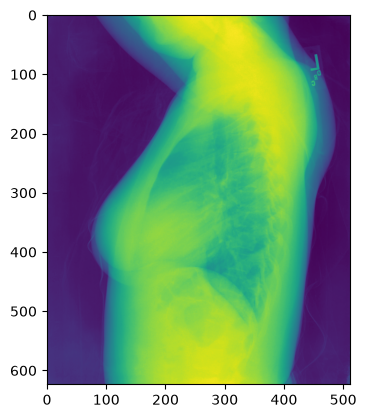

In [38]:
plt.imshow(arr[:,:,1])

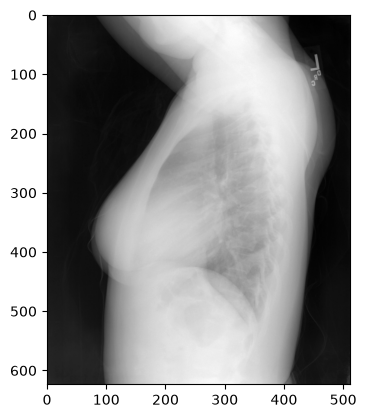

In [39]:
plt.imshow(arr[:,:,1], cmap="gray") #doesnt know its grayscale cause we feed a 2-D array(onnly give 1 channel)
#unless we give the wholem array(arr[:,:])

(np.float64(-0.5), np.float64(511.5), np.float64(623.5), np.float64(-0.5))

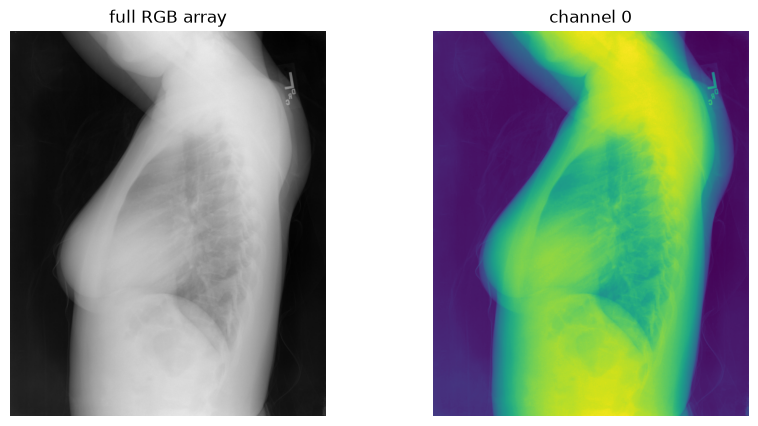

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(arr)
axes[0].set_title("full RGB array")
axes[0].axis("off")

axes[1].imshow(arr[:, :, 0])
axes[1].set_title("channel 0")
axes[1].axis("off")

In [41]:
first_report = REPORTS/'100.xml'
root = ET.parse(first_report).getroot()
parent_images = [t.attrib.get('id') for t in root.findall('parentImage')]


In [42]:
report1_images = []
for image in parent_images:
    image_path = image + '.' + 'png'
    report1_images.append(Image.open(IMAGES / image_path))


In [43]:
for img in report1_images:
    print(img.size, img.mode)

(512, 420) RGB
(512, 624) RGB


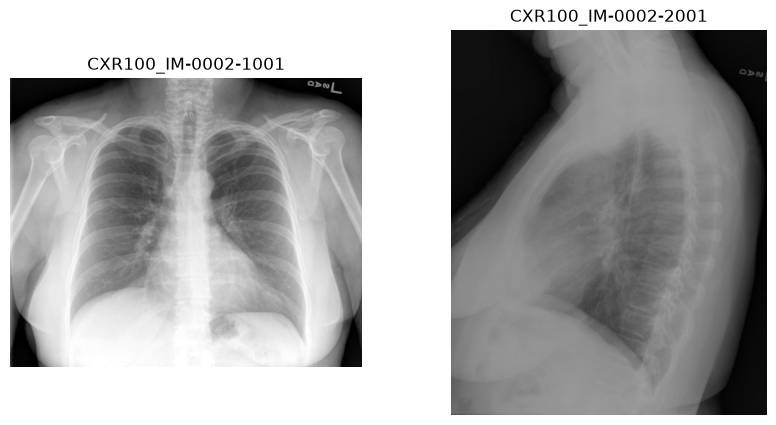

In [44]:
n_images = len(report1_images)

if n_images == 0:
    print("This report has no images")
else:
    # squeeze=False: axes is always 2-D (rows, columns), even with a single image
    fig, axes = plt.subplots(1, n_images, figsize=(5 * n_images, 5), squeeze=False)

    for i, img in enumerate(report1_images):
        axes[0, i].imshow(img)
        axes[0, i].set_title(parent_images[i])
        axes[0, i].axis("off")

    plt.show()

We can see that some xlm files only have 1 parent image or maybe None. Also the two view have different sizes

# Part B: The inventory table


The goal: one table with one row per report, containing everything  explored in Part A. Then every inventory question becomes a short pandas command.
Nested dictionary:
reports = {
    "CXR1": {"comparison": "None.", "n_images": 2, ...},
    "CXR2": {"comparison": ...,     "n_images": 1, ...},
}
Or just a list:
records = [
    {"report_id": "CXR1", "comparison": "None.", "n_images": 2, ...},
    {"report_id": "CXR2", "comparison": ...,     "n_images": 1, ...},
]
The list seems to be a better way here cause it goes straight into pandas


In [45]:
#start by extracting the values from '1.xml' into a dictionary
first_xlm =  REPORTS/'1002.xml'

In [46]:
def parse_report(path):
    sections = {}
    root = ET.parse(path).getroot()

    #uId
    sections['report_id'] = root.find('uId').attrib.get('id')

    #AbstractText
    for label in root.iter('AbstractText'):
        sections[label.get('Label').lower()] = label.text

    #parentImages
    parent_images=[]
    for parent_image in root.iter('parentImage'):
        parent_images.append(parent_image.attrib.get('id'))
    sections["image_ids"] = parent_images
    sections["n_images"] = len(parent_images)

    #mesh
    mesh = root.find('MeSH')
    mesh_major = [m.text for m in mesh.findall("major")]
    mesh_automatic = [m.text for m in mesh.findall("automatic")]

    sections['mesh_major'] = mesh_major
    sections['mesh_automatic'] = mesh_automatic

    return sections

In [47]:
sections = parse_report(first_xlm)

In [48]:
sections

{'report_id': 'CXR1002',
 'comparison': None,
 'indication': 'History of chest pain',
 'findings': None,
 'impression': 'Status post left mastectomy. Heart size normal. Lungs are clear.',
 'image_ids': ['CXR1002_IM-0004-1001', 'CXR1002_IM-0004-2001'],
 'n_images': 2,
 'mesh_major': ['Mastectomy/left'],
 'mesh_automatic': ['mastectomies', 'Mastectomy', 'surgery']}

# Part C: Parse the files and create the dataset

In [49]:
#Build the list of records
filepaths = list(REPORTS.glob("*.xml")) #join all the xml files into a list
filepaths[0:5]

[WindowsPath('../data/raw/ecgen-radiology/1.xml'),
 WindowsPath('../data/raw/ecgen-radiology/10.xml'),
 WindowsPath('../data/raw/ecgen-radiology/100.xml'),
 WindowsPath('../data/raw/ecgen-radiology/1000.xml'),
 WindowsPath('../data/raw/ecgen-radiology/1001.xml')]

In [50]:
records = []

for filepath in filepaths:
    records.append(parse_report(filepath))
    
len(records)

3955

In [51]:
import pandas as pd

df = pd.DataFrame(records)

df.shape

(3955, 9)

In [52]:
df[0:2]

,report_id,comparison,indication,findings,impression,image_ids,n_images,mesh_major,mesh_automatic
0,CXR1,None.,Positive TB test,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.,"[CXR1_1_IM-0001-3001, CXR1_1_IM-0001-4001]",2,[normal],[]
1,CXR10,Chest radiographs XXXX.,"XXXX-year-old male, chest pain.",The cardiomediastinal silhouette is within nor...,No acute cardiopulmonary process.,"[CXR10_IM-0002-1001, CXR10_IM-0002-2001]",2,[Calcified Granuloma/lung/upper lobe/right],[calcified granuloma]


In [53]:
df["report_id"].duplicated().sum()

np.int64(0)

In [54]:
abstract_text_df = df[['comparison','indication','findings','impression']]

In [55]:
abstract_text_df.isna().sum()

comparison    622
indication     90
findings      530
impression     34
dtype: int64

Why all 4, if the model only learns to write Findings?

The other sections may matter later:
Impression is the radiologist's short conclusion.
When Findings is empty, Impression could be a fallback text to train on. That's a real option to weigh in Phase 3.
Indication is why the X-ray was taken (e.g. "chest pain"). It could become extra input to the model one day.
Comparison says whether there was an earlier X-ray. It's probably the least useful for us.

In [56]:
df['n_images'].value_counts().sort_index()

n_images
0     104
1     446
2    3208
3     181
4      15
5       1
Name: count, dtype: int64

In [57]:
df['n_images'].sum() # equals the PNG count from Part A

np.int64(7470)

In [58]:
usable = df[df['findings'].notna() & (df['n_images']>0)]

In [59]:
df['findings'].notna().sum()

np.int64(3425)

In [60]:
sample_df = usable.sample(5, random_state=42)

In [61]:
for text in sample_df["findings"]:
    print(text)
    print("-" * 60)

Heart size normal. Lungs are clear. XXXX are normal. No pneumonia, effusions, edema, pneumothorax, adenopathy, nodules or masses.
------------------------------------------------------------
Lungs appear to be clear other than a calcified granuloma on left. Heart is not enlarged. There are atherosclerotic changes of the aorta. There is increased kyphosis of the thoracic spine and there are multiple XXXX deformities. A stimulator is seen.
------------------------------------------------------------
The lungs appear clear. The heart and pulmonary XXXX are normal. Pleural spaces are clear. Mediastinal contours are normal. Bony overlap in the lung apices could obscure a small pulmonary nodule.
------------------------------------------------------------
Heart size and pulmonary vascularity appear within normal limits. The lungs are free of focal airspace disease. No pleural effusion or pneumothorax is seen. Vascular calcification is noted.
--------------------------------------------------

In [62]:
df.columns

Index(['report_id', 'comparison', 'indication', 'findings', 'impression',
       'image_ids', 'n_images', 'mesh_major', 'mesh_automatic'],
      dtype='str')

In [63]:
df['image_ids'][0:5]

0           [CXR1_1_IM-0001-3001, CXR1_1_IM-0001-4001]
1             [CXR10_IM-0002-1001, CXR10_IM-0002-2001]
2           [CXR100_IM-0002-1001, CXR100_IM-0002-2001]
3    [CXR1000_IM-0003-1001, CXR1000_IM-0003-2001, C...
4         [CXR1001_IM-0004-1001, CXR1001_IM-0004-1002]
Name: image_ids, dtype: object

In [64]:
for report,image in zip(df['report_id'][0:5], df['image_ids'][0:5]):
    print(report,image)

CXR1 ['CXR1_1_IM-0001-3001', 'CXR1_1_IM-0001-4001']
CXR10 ['CXR10_IM-0002-1001', 'CXR10_IM-0002-2001']
CXR100 ['CXR100_IM-0002-1001', 'CXR100_IM-0002-2001']
CXR1000 ['CXR1000_IM-0003-1001', 'CXR1000_IM-0003-2001', 'CXR1000_IM-0003-3001']
CXR1001 ['CXR1001_IM-0004-1001', 'CXR1001_IM-0004-1002']


In [65]:
image_to_report = {}
for report_id, image_ids in zip(df['report_id'], df['image_ids']):
    for image_id in image_ids:
        if image_id not in image_to_report:
            image_to_report[image_id] = report_id
        else:
            print("duplicate:", image_id)  # an image claimed by two reports


In [66]:
image_to_report

{'CXR1_1_IM-0001-3001': 'CXR1',
 'CXR1_1_IM-0001-4001': 'CXR1',
 'CXR10_IM-0002-1001': 'CXR10',
 'CXR10_IM-0002-2001': 'CXR10',
 'CXR100_IM-0002-1001': 'CXR100',
 'CXR100_IM-0002-2001': 'CXR100',
 'CXR1000_IM-0003-1001': 'CXR1000',
 'CXR1000_IM-0003-2001': 'CXR1000',
 'CXR1000_IM-0003-3001': 'CXR1000',
 'CXR1001_IM-0004-1001': 'CXR1001',
 'CXR1001_IM-0004-1002': 'CXR1001',
 'CXR1002_IM-0004-1001': 'CXR1002',
 'CXR1002_IM-0004-2001': 'CXR1002',
 'CXR1003_IM-0005-2002': 'CXR1003',
 'CXR1004_IM-0005-1001': 'CXR1004',
 'CXR1004_IM-0005-2001': 'CXR1004',
 'CXR1005_IM-0006-1001': 'CXR1005',
 'CXR1005_IM-0006-3003': 'CXR1005',
 'CXR1006_IM-0007-1001': 'CXR1006',
 'CXR1006_IM-0007-3003': 'CXR1006',
 'CXR1007_IM-0008-1001': 'CXR1007',
 'CXR1007_IM-0008-2001': 'CXR1007',
 'CXR1007_IM-0008-3001': 'CXR1007',
 'CXR1008_IM-0009-2001': 'CXR1008',
 'CXR1008_IM-0009-4004': 'CXR1008',
 'CXR1009_IM-0010-1001': 'CXR1009',
 'CXR1009_IM-0010-2001': 'CXR1009',
 'CXR101_IM-0011-2001': 'CXR101',
 'CXR101_IM-00

In [67]:
print(len(image_to_report), df['n_images'].sum())

#they are equal so that means that every image is distinct and not repeated in other reports
#this says nothing about patients: one patient could have several reports, each with its own images.
#there is no patient ID in the XML -> open question for Step 0.2


7470 7470


In [68]:
images = list(IMAGES.glob('*.png'))
len(images)

7470

In [69]:
image_records = []

for image_path in images:
    image_id = image_path.stem
    with Image.open(image_path) as img:
        width, height = img.size
        mode = img.mode

    image_records.append({
        "image_id": image_id,                          # from path
        "report_id": image_to_report.get(image_id),    # .get: an orphan image becomes None instead of crashing
        "width": width,
        "height": height,
        "mode": mode,
    })
img_df = pd.DataFrame(image_records)


In [70]:
img_df

,image_id,report_id,width,height,mode
0,CXR1000_IM-0003-1001,CXR1000,512,624,RGB
1,CXR1000_IM-0003-2001,CXR1000,512,624,RGB
2,CXR1000_IM-0003-3001,CXR1000,512,624,RGB
3,CXR1001_IM-0004-1001,CXR1001,512,485,RGB
4,CXR1001_IM-0004-1002,CXR1001,512,545,RGB
...,...,...,...,...,...
7465,CXR999_IM-2480-3001,CXR999,512,420,RGB
7466,CXR99_IM-2476-1001,CXR99,512,521,RGB
7467,CXR99_IM-2476-1002,CXR99,512,604,RGB
7468,CXR9_IM-2407-1001,CXR9,512,512,RGB


In [71]:
img_df['mode'].value_counts()

mode
RGB    7470
Name: count, dtype: int64

In [72]:
img_df.describe()
#count	how many non-missing values	7,470 in both columns, so no missing sizes
#mean	the average	width 512, height about 533
#std	standard deviation: how spread out the values are	width 0, height about 81
#min / max	smallest / largest	height ranges from 362 to 873
#25% / 50% / 75%	quartiles: 25% of values are below the first, 
# 50% below the second (the median), 75% below the third	height 484 / 512 / 624

,width,height
count,7470.0,7470.000000
mean,512.0,532.778983
std,0.0,80.665129
min,512.0,362.000000
25%,512.0,484.000000
50%,512.0,512.000000
75%,512.0,624.000000
max,512.0,873.000000


std = 0 and min = max = 512 mean every single image is exactly 512 pixels wide. That can't be a coincidence with real X-rays from different machines. The provider resized every image to a width of 512, keeping the proportions. So the height is whatever the original shape produced, which is why heights vary and widths don't

In [73]:
img_df['report_id'].isna().sum() #no orphan images. that they have no report id.

np.int64(0)

In [ ]:
#different image sizes
#take care of this diffrence. IMPORTANT

#img_df['width']	one column (a Series)
#img_df[['width', 'height']]	two columns (a smaller DataFrame)
#img_df['width']['height']	❌ the row labelled 'height' inside the width column
len(img_df[['width','height']].drop_duplicates())

304

In [ ]:
(img_df['height'] > img_df['width']).sum() #portrait images

np.int64(3332)

In [ ]:
(img_df['height'] < img_df['width']).sum() #landscape images

np.int64(2610)

In [ ]:
(img_df['height'] == img_df['width']).sum() #square images

np.int64(1528)

In [85]:
img_df["height"].value_counts().head(10)

height
624    1983
512    1528
420    1424
511     429
618     166
423     123
419      70
513      68
623      67
613      62
Name: count, dtype: int64

<Axes: >

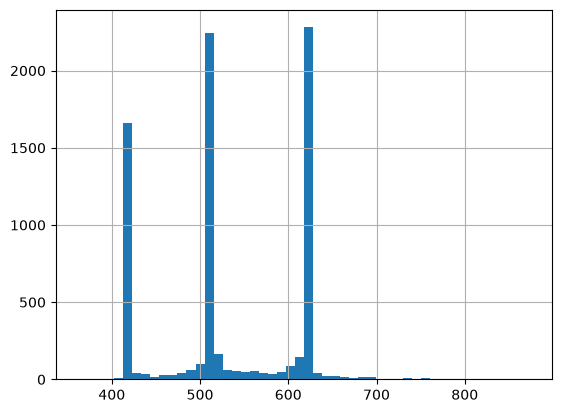

In [86]:
img_df["height"].hist(bins=50)

In [93]:
portrait = img_df[img_df['height'] > img_df['width']]
landscape = img_df[img_df['height'] < img_df['width']]

portrait_samples = portrait.sample(3, random_state=0)
landscape_samples = landscape.sample(3,random_state=0)

In [94]:
portrait_samples

,image_id,report_id,width,height,mode
4605,CXR3242_IM-1534-1002,CXR3242,512,514,RGB
2683,CXR2296_IM-0876-2001,CXR2296,512,624,RGB
6844,CXR701_IM-2266-2001,CXR701,512,624,RGB


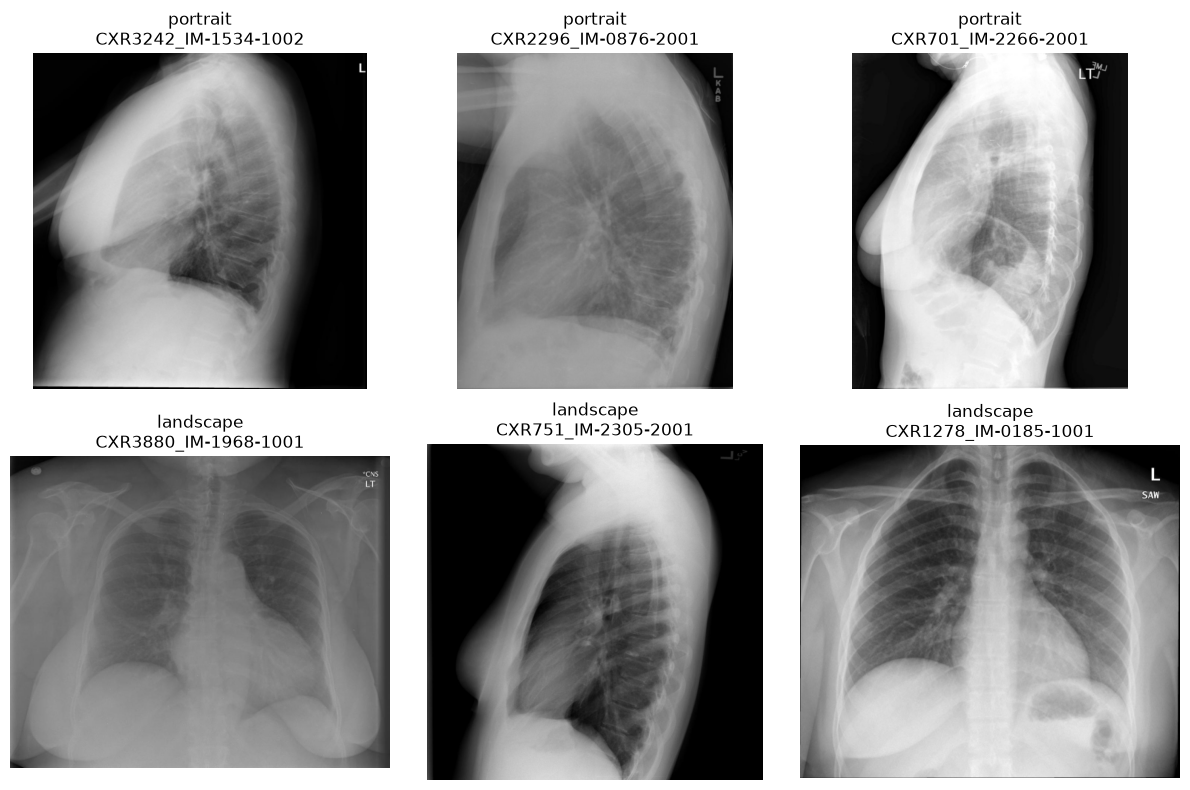

In [95]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# row 0: portrait samples
for col, image_id in enumerate(portrait_samples["image_id"]):
    img = Image.open(IMAGES / f"{image_id}.png")
    axes[0, col].imshow(img)
    axes[0, col].set_title(f"portrait\n{image_id}")
    axes[0, col].axis("off")

# row 1: landscape samples (same code, row 1 and the other table)
for col, image_id in enumerate(landscape_samples["image_id"]):
    img = Image.open(IMAGES / f"{image_id}.png")
    axes[1, col].imshow(img)
    axes[1, col].set_title(f"landscape\n{image_id}")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()
